# 2.2.4. Bài tập thực hành 2 - SVM dự đoán tình trạng động vật

Sử dụng data/data.csv, gồm AnimalName, symptoms1...symptoms5 và nhãn Dangerous. Mục tiêu là dự đoán **Dangerous (No/Yes)** từ tên loài và triệu chứng, không phải phân loại tên loài.

[Bài Kaggle được nêu trong đề](https://www.kaggle.com/code/kareemellithy/animal-condition-predict-svm-knn). Notebook triển khai trên file thực tế đã cung cấp. Nhãn rất mất cân bằng và lớp No ít mẫu, cần báo cáo đúng giới hạn đánh giá.

## Nhiệm vụ 1. Khảo sát, làm sạch và mã hóa

### Bước 1. Nạp dữ liệu

In [1]:
from pathlib import Path
from time import perf_counter
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from sklearn import svm, datasets
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold, cross_val_score
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, precision_score,
    recall_score, f1_score, roc_auc_score, average_precision_score,
    classification_report, ConfusionMatrixDisplay, RocCurveDisplay, PrecisionRecallDisplay)
from sklearn.exceptions import ConvergenceWarning

get_ipython().run_line_magic('matplotlib', 'inline')
plt.rcParams['figure.dpi'] = 120
RANDOM_STATE = 101
# Bao loi neu bo giai chua hoi tu, tranh su dung ket qua huan luyen dang do.
warnings.filterwarnings('error', category=ConvergenceWarning)


lab_candidates = []
for parent in [Path.cwd(), *Path.cwd().parents]:
    lab_candidates.extend([parent, parent / 'Lab05' / '2.2. Giai_Thuat2'])
# Duong dan du an duoc chi dinh; dung khi mo ban notebook tu thu muc outputs.
lab_candidates.append(Path(r'D:\SGU_HocMay_2026-2027\Lab05\2.2. Giai_Thuat2'))
LAB_DIR = next((p for p in lab_candidates if (p / 'data' / 'Iris.csv').is_file()), None)
if LAB_DIR is None:
    raise FileNotFoundError('Chua tim thay thu muc data cua Lab05/2.2. Giai_Thuat2.')
DATA_DIR = LAB_DIR / 'data'
print('Thu muc du lieu:', DATA_DIR)

Thu muc du lieu: D:\SGU_HocMay_2026-2027\Lab05\2.2. Giai_Thuat2\data


Ban dau: (871, 7)


,AnimalName,symptoms1,symptoms2,symptoms3,symptoms4,symptoms5,Dangerous
0,Dog,Fever,Diarrhea,Vomiting,Weight loss,Dehydration,Yes
1,Dog,Fever,Diarrhea,Coughing,Tiredness,Pains,Yes
2,Dog,Fever,Diarrhea,Coughing,Vomiting,Anorexia,Yes
3,Dog,Fever,Difficulty breathing,Coughing,Lethargy,Sneezing,Yes
4,Dog,Fever,Diarrhea,Coughing,Lethargy,Blue Eye,Yes


,missing
AnimalName,0
symptoms1,0
symptoms2,0
symptoms3,0
symptoms4,0
symptoms5,0
Dangerous,2


,count
Dangerous,
Yes,849
No,20
NaN,2


Loai nhan thieu: 2 | Loai dong trung: 28 | Sau lam sach: (841, 7)


,count
Dangerous,
No (0),20
Yes (1),821


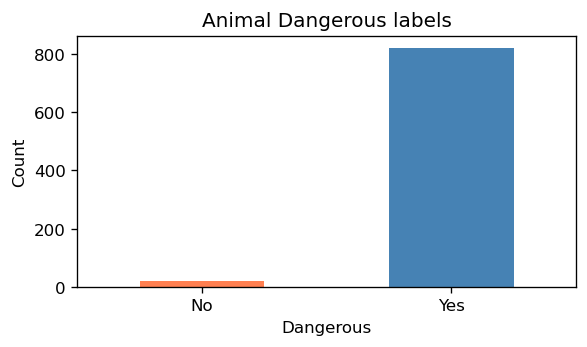

In [2]:
raw_df=pd.read_csv(DATA_DIR/'data.csv')
feature_columns=['AnimalName','symptoms1','symptoms2','symptoms3','symptoms4','symptoms5']
assert set(feature_columns+['Dangerous']).issubset(raw_df.columns)
print('Ban dau:',raw_df.shape)
display(raw_df.head())
display(raw_df.isna().sum().to_frame('missing'))
display(raw_df['Dangerous'].value_counts(dropna=False).to_frame('count'))

# Khong dien hay suy doan nhan Dangerous bi thieu.
missing_target=int(raw_df['Dangerous'].isna().sum())
df=raw_df.dropna(subset=['Dangerous']).copy()
for column in feature_columns+['Dangerous']:
    df[column]=df[column].str.strip().replace('',np.nan)
df=df.dropna(subset=['Dangerous'])
duplicates=int(df.duplicated().sum())
df=df.drop_duplicates().reset_index(drop=True)
assert set(df['Dangerous'].unique())=={'No','Yes'}
X=df[feature_columns].copy()
y=df['Dangerous'].map({'No':0,'Yes':1}).astype(int)
CLASS_NAMES=['No','Yes']
RESULT_SLUG='SVM_DongVat'
SCORING='balanced_accuracy'
print('Loai nhan thieu:',missing_target,'| Loai dong trung:',duplicates,'| Sau lam sach:',df.shape)
display(y.value_counts().sort_index().rename(index={0:'No (0)',1:'Yes (1)'}).to_frame('count'))
fig,ax=plt.subplots(figsize=(5,3))
y.value_counts().sort_index().plot.bar(ax=ax,rot=0,color=['coral','steelblue'])
ax.set_xticklabels(CLASS_NAMES)
ax.set(title='Animal Dangerous labels',ylabel='Count')
plt.tight_layout()
plt.show()

### Bước 2. Tách test và xây Pipeline

Loại 2 dòng thiếu nhãn thay vì tự điền nhãn, làm sạch khoảng trắng và bỏ dòng trùng. Mã hóa No=0, Yes=1. Tách 80:20 có stratify; với file hiện tại, train có 16 mẫu No và test chỉ 4 mẫu No.

Các đặc trưng đều dạng chữ, dùng imputer và one-hot sparse. Không dùng LabelEncoder gán thứ tự giả cho triệu chứng; không cần StandardScaler mặc định lên ma trận one-hot 0/1. Unknown categories được bỏ qua để chạy được khi test có giá trị chưa gặp trong train.

In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)
assert set(X_train.index).isdisjoint(X_test.index)
print('Train:', X_train.shape, '| Test:', X_test.shape)
display(pd.DataFrame({'train': y_train.value_counts(), 'test': y_test.value_counts()}).sort_index())
cv_splitter = StratifiedKFold(n_splits=4, shuffle=True, random_state=RANDOM_STATE)

Train: (672, 6) | Test: (169, 6)


,train,test
Dangerous,,
0,16,4
1,656,165


In [4]:
preprocessor=ColumnTransformer([
    ('cat',Pipeline([
        ('imputer',SimpleImputer(strategy='most_frequent')),
        ('onehot',OneHotEncoder(handle_unknown='ignore',sparse_output=True))
    ]),feature_columns)
],sparse_threshold=1.0)
baseline=Pipeline([
    ('preprocess',preprocessor),
    ('svc',svm.SVC(kernel='rbf',C=1,gamma='scale',class_weight='balanced'))
])

t0 = perf_counter()
baseline.fit(X_train, y_train)
print('Train accuracy (baseline):', round(baseline.score(X_train, y_train), 4))
print('Thoi gian fit baseline:', round(perf_counter() - t0, 2), 'giay')

Train accuracy (baseline): 1.0
Thoi gian fit baseline: 0.09 giay


## Nhiệm vụ 2. Tìm kernel, C, gamma và trọng số lớp

Thử linear/RBF với C=0,1; 1; 10; với RBF thử gamma=scale hoặc 0,1. Chọn bằng balanced accuracy của 4-fold CV để không thưởng cho việc chỉ đoán lớp Yes chiếm đa số. balanced_accuracy là trung bình recall hai lớp. Mỗi fold validation chỉ có khoảng 4 mẫu No nên điểm CV vẫn có thể biến động mạnh.

Scoring: balanced_accuracy
Baseline mean CV: 0.75
Tham so tot nhat: {'svc__C': 0.1, 'svc__class_weight': 'balanced', 'svc__gamma': 'scale', 'svc__kernel': 'rbf'}
Mean CV tot nhat: 0.7805
Thoi gian tim kiem: 5.63 giay


,params,mean_train_score,mean_test_score,std_test_score,mean_fit_time
8,"{'svc__C': 0.1, 'svc__class_weight': 'balanced...",1.000000,0.780488,0.183978,0.041304
9,"{'svc__C': 0.1, 'svc__class_weight': 'balanced...",0.999746,0.778201,0.181798,0.043771
16,"{'svc__C': 10, 'svc__class_weight': 'balanced'...",1.000000,0.750000,0.153093,0.033395
15,"{'svc__C': 10, 'svc__class_weight': None, 'svc...",1.000000,0.750000,0.153093,0.030429
14,"{'svc__C': 10, 'svc__class_weight': None, 'svc...",1.000000,0.750000,0.153093,0.034718
13,"{'svc__C': 1, 'svc__class_weight': 'balanced',...",1.000000,0.750000,0.153093,0.031157
12,"{'svc__C': 1, 'svc__class_weight': 'balanced',...",1.000000,0.750000,0.153093,0.034648
17,"{'svc__C': 10, 'svc__class_weight': 'balanced'...",1.000000,0.750000,0.153093,0.030167
5,"{'svc__C': 10, 'svc__class_weight': 'balanced'...",1.000000,0.750000,0.153093,0.027411
4,"{'svc__C': 10, 'svc__class_weight': None, 'svc...",1.000000,0.750000,0.153093,0.027987


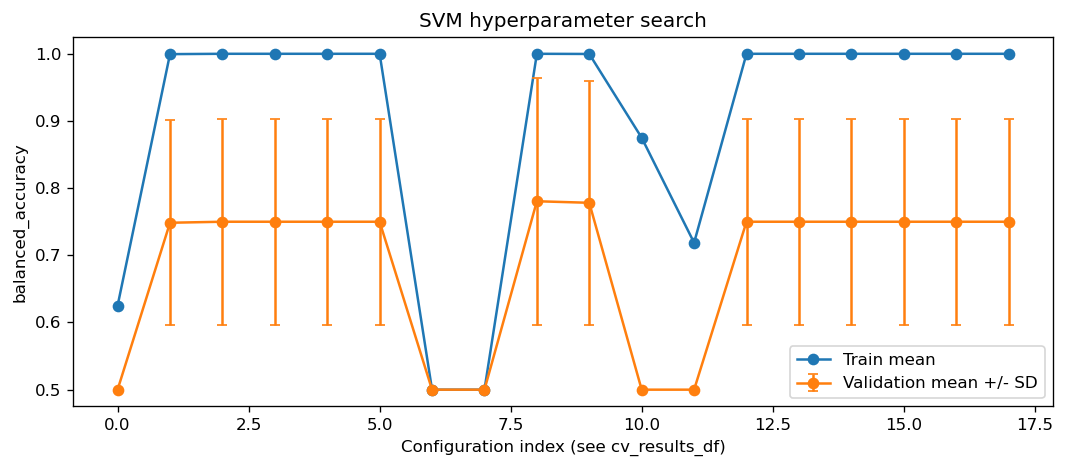

In [5]:
param_grid=[
    {'svc__kernel':['linear'],'svc__C':[0.1,1,10],'svc__class_weight':[None,'balanced']},
    {'svc__kernel':['rbf'],'svc__C':[0.1,1,10],'svc__gamma':['scale',0.1],
     'svc__class_weight':[None,'balanced']}
]

# Khong dung test de chon kernel hay tham so.
t0 = perf_counter()
baseline_cv_scores = cross_val_score(
    baseline, X_train, y_train, cv=cv_splitter, scoring=SCORING, n_jobs=1, error_score='raise'
)
search = GridSearchCV(
    clone(baseline), param_grid=param_grid, scoring=SCORING, cv=cv_splitter,
    refit=True, return_train_score=True, error_score='raise', n_jobs=1
)
search.fit(X_train, y_train)
best_svm = search.best_estimator_
cv_results_df = pd.DataFrame(search.cv_results_)
print('Scoring:', SCORING)
print('Baseline mean CV:', round(baseline_cv_scores.mean(), 4))
print('Tham so tot nhat:', search.best_params_)
print('Mean CV tot nhat:', round(search.best_score_, 4))
print('Thoi gian tim kiem:', round(perf_counter()-t0, 2), 'giay')
display(cv_results_df[['params', 'mean_train_score', 'mean_test_score',
                       'std_test_score', 'mean_fit_time']].sort_values('mean_test_score', ascending=False).head(12))

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(np.arange(len(cv_results_df)), cv_results_df['mean_train_score'], 'o-', label='Train mean')
ax.errorbar(np.arange(len(cv_results_df)), cv_results_df['mean_test_score'],
            yerr=cv_results_df['std_test_score'], fmt='o-', capsize=3, label='Validation mean +/- SD')
ax.set(xlabel='Configuration index (see cv_results_df)', ylabel=SCORING, title='SVM hyperparameter search')
ax.legend()
plt.tight_layout()
plt.show()

## Nhiệm vụ 3. Đánh giá và phân tích lỗi

Giữ thứ tự y_true, y_pred trong confusion matrix và classification_report. Xem precision/recall lớp No (0), không chỉ accuracy của lớp Yes. Đường precision-recall dùng **No làm lớp cần quan tâm** bằng cách đảo nhãn/điểm quyết định đúng hướng; đường ROC còn dùng Yes=1.


SVM baseline
              precision    recall  f1-score   support

          No       1.00      1.00      1.00         4
         Yes       1.00      1.00      1.00       165

    accuracy                           1.00       169
   macro avg       1.00      1.00      1.00       169
weighted avg       1.00      1.00      1.00       169


SVM tuned
              precision    recall  f1-score   support

          No       1.00      1.00      1.00         4
         Yes       1.00      1.00      1.00       165

    accuracy                           1.00       169
   macro avg       1.00      1.00      1.00       169
weighted avg       1.00      1.00      1.00       169



,Train accuracy,CV score,Test accuracy,Test balanced accuracy,Test precision macro,Test recall macro,Test F1 macro,Test ROC AUC (class 1),Minority label,Minority precision,Minority recall,Minority average precision
Model,,,,,,,,,,,,
SVM baseline,1.0,0.7500,1.0,1.0,1.0,1.0,1.0,1.0,0,1.0,1.0,1.0
SVM tuned,1.0,0.7805,1.0,1.0,1.0,1.0,1.0,1.0,0,1.0,1.0,1.0


Accuracy neu luon doan lop pho bien: 0.9763


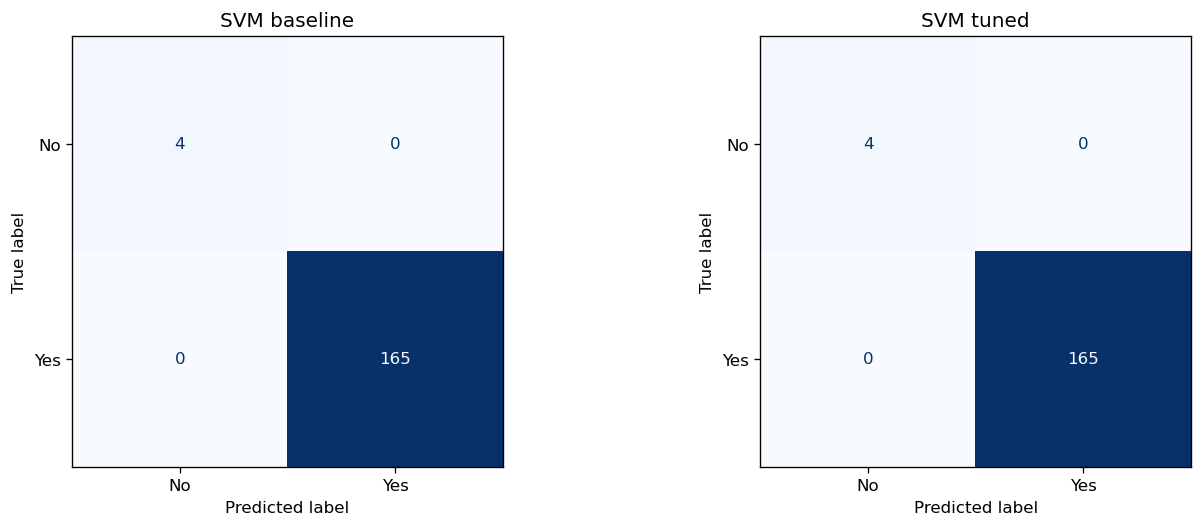

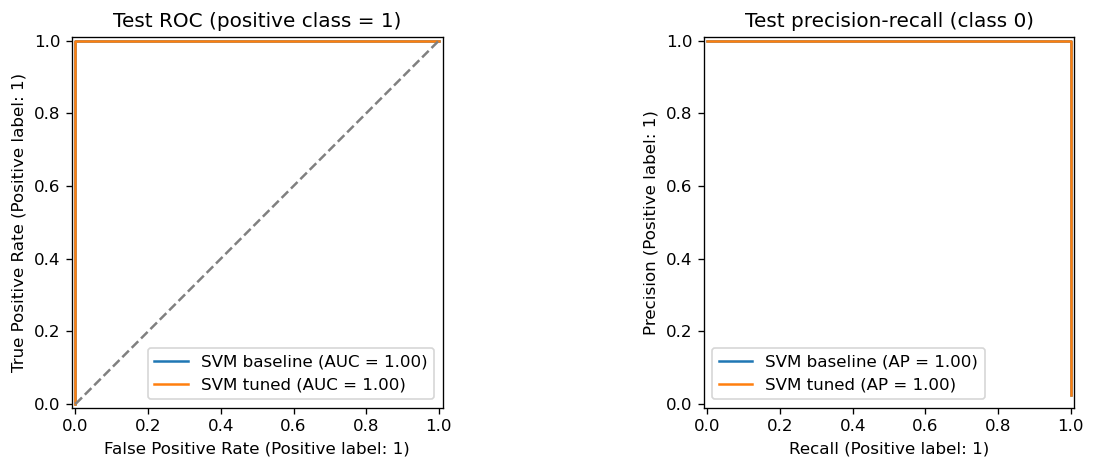

In [6]:
# Danh gia mot lan sau khi chot cau hinh bang CV.
models = {'SVM baseline': baseline, 'SVM tuned': best_svm}
cv_scores = {'SVM baseline': baseline_cv_scores.mean(), 'SVM tuned': search.best_score_}
labels = sorted(pd.unique(y))
is_binary = len(labels) == 2
minority_label = y_train.value_counts().idxmin() if is_binary else None
records, predictions, decision_scores = [], {}, {}

for name, model in models.items():
    pred = model.predict(X_test)
    predictions[name] = pred
    row = {
        'Model': name, 'Train accuracy': model.score(X_train, y_train),
        'CV score': cv_scores[name], 'Test accuracy': accuracy_score(y_test, pred),
        'Test balanced accuracy': balanced_accuracy_score(y_test, pred),
        'Test precision macro': precision_score(y_test, pred, average='macro', zero_division=0),
        'Test recall macro': recall_score(y_test, pred, average='macro', zero_division=0),
        'Test F1 macro': f1_score(y_test, pred, average='macro', zero_division=0)
    }
    if is_binary:
        scores = model.decision_function(X_test)
        decision_scores[name] = scores
        minority_scores = scores if minority_label == model.classes_[1] else -scores
        row['Test ROC AUC (class 1)'] = roc_auc_score(y_test, scores)
        row['Minority label'] = minority_label
        row['Minority precision'] = precision_score(y_test, pred, pos_label=minority_label, zero_division=0)
        row['Minority recall'] = recall_score(y_test, pred, pos_label=minority_label, zero_division=0)
        row['Minority average precision'] = average_precision_score((y_test==minority_label).astype(int), minority_scores)
    records.append(row)
    print('\n' + name)
    print(classification_report(y_test, pred, labels=labels, target_names=CLASS_NAMES, zero_division=0))

comparison_df = pd.DataFrame(records).set_index('Model')
display(comparison_df.round(4))
majority_baseline = y_test.value_counts(normalize=True).max()
print('Accuracy neu luon doan lop pho bien:', round(majority_baseline, 4))

fig, axs = plt.subplots(1, 2, figsize=(12, 4.5 if len(labels)<=3 else 5))
for ax, name in zip(axs, models):
    ConfusionMatrixDisplay.from_predictions(
        y_test, predictions[name], labels=labels, display_labels=CLASS_NAMES,
        cmap='Blues', colorbar=False, ax=ax, xticks_rotation=45 if len(labels)==3 else 0
    )
    ax.set_title(name)
plt.tight_layout()
plt.show()

if is_binary:
    fig, axes = plt.subplots(1, 2, figsize=(11, 4))
    for name, model in models.items():
        scores = decision_scores[name]
        RocCurveDisplay.from_predictions(y_test, scores, name=name, ax=axes[0])
        minority_scores = scores if minority_label==model.classes_[1] else -scores
        PrecisionRecallDisplay.from_predictions(
            (y_test==minority_label).astype(int), minority_scores, name=name, ax=axes[1]
        )
    axes[0].plot([0, 1], [0, 1], '--', color='gray')
    axes[0].set_title('Test ROC (positive class = 1)')
    axes[1].set_title(f'Test precision-recall (class {minority_label})')
    plt.tight_layout()
    plt.show()

## Nhận xét và lưu kết quả

**Giới hạn quan trọng:** test chỉ có 4 mẫu No, nên thay đổi 1 dự đoán làm recall lớp này đổi 25 điểm phần trăm. Một lần chia nhỏ không đủ khẳng định mô hình tổng quát hóa ổn định. Dữ liệu có 45 tên loài và có thể cùng loài ở train/test; đánh giá này không chứng minh khả năng dự đoán tốt cho loài hoàn toàn mới. Việc tìm thêm dữ liệu No đa dạng sẽ có giá trị hơn việc chỉ nhìn accuracy rất cao.

In [7]:
best_row = cv_results_df.loc[search.best_index_]
gap = float(best_row['mean_train_score'] - best_row['mean_test_score'])
tuned = comparison_df.loc['SVM tuned']
acc = tuned['Test accuracy']
f1 = tuned['Test F1 macro']
balanced_acc = tuned['Test balanced accuracy']
notes = '\n\n'.join([
    '### Nhận xét kết quả',
    f'- Train **{len(X_train):,} mẫu**, test **{len(X_test):,} mẫu**. Siêu tham số được chọn bằng **{SCORING}**, 4-fold CV trên train.',
    f'- Tham số chọn trong lưới: **{search.best_params_}**. Điểm CV **{search.best_score_:.4f}**; chênh lệch train - validation tại cấu hình này **{gap:.4f}**.',
    f'- SVM sau tìm kiếm đạt test accuracy **{acc:.4f}**, balanced accuracy **{balanced_acc:.4f}**, F1-macro **{f1:.4f}**.',
    f'- Nếu luôn đoán lớp phổ biến, accuracy là **{majority_baseline:.4f}**. Cần đọc thêm confusion matrix và chỉ số từng lớp để tránh đánh giá sai khi nhãn mất cân bằng.',
    '- Khoảng cách điểm train/validation là dấu hiệu tham khảo về quá khớp, không đo trực tiếp bias/variance. Cấu hình được chọn chỉ tốt nhất trong lưới đã thử.',
    '- Pipeline chỉ fit scaler/imputer/encoder trên phần train của từng fold. Không chọn lại siêu tham số theo test. SVC/LinearSVC dùng decision_function khi đánh giá ROC AUC; đây là điểm quyết định, không phải xác suất đã hiệu chỉnh.'
])
if is_binary:
    minority_count = int((y_test==minority_label).sum())
    precision_minority = tuned['Minority precision']
    recall_minority = tuned['Minority recall']
    notes += f'\n\n- Lớp ít mẫu là **{minority_label}**, có **{minority_count} mẫu test**. Precision **{precision_minority:.4f}**, recall **{recall_minority:.4f}**.'
display(Markdown(notes))

RESULTS_DIR = LAB_DIR / 'ket_qua' / RESULT_SLUG
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
comparison_df.to_csv(RESULTS_DIR/'so_sanh_mo_hinh.csv', encoding='utf-8-sig')
cv_results_df.to_csv(RESULTS_DIR/'cv_results.csv', index=False, encoding='utf-8-sig')
prediction_table = pd.DataFrame({'row_index':X_test.index, 'actual':y_test.to_numpy(),
    'baseline_prediction':predictions['SVM baseline'], 'tuned_prediction':predictions['SVM tuned']})
if is_binary:
    prediction_table['baseline_score']=decision_scores['SVM baseline']
    prediction_table['tuned_score']=decision_scores['SVM tuned']
prediction_table.to_csv(RESULTS_DIR/'du_doan_test.csv',index=False,encoding='utf-8-sig')
(RESULTS_DIR/'nhan_xet.md').write_text(notes,encoding='utf-8')
print('Ket qua da luu:',RESULTS_DIR)

### Nhận xét kết quả

- Train **672 mẫu**, test **169 mẫu**. Siêu tham số được chọn bằng **balanced_accuracy**, 4-fold CV trên train.

- Tham số chọn trong lưới: **{'svc__C': 0.1, 'svc__class_weight': 'balanced', 'svc__gamma': 'scale', 'svc__kernel': 'rbf'}**. Điểm CV **0.7805**; chênh lệch train - validation tại cấu hình này **0.2195**.

- SVM sau tìm kiếm đạt test accuracy **1.0000**, balanced accuracy **1.0000**, F1-macro **1.0000**.

- Nếu luôn đoán lớp phổ biến, accuracy là **0.9763**. Cần đọc thêm confusion matrix và chỉ số từng lớp để tránh đánh giá sai khi nhãn mất cân bằng.

- Khoảng cách điểm train/validation là dấu hiệu tham khảo về quá khớp, không đo trực tiếp bias/variance. Cấu hình được chọn chỉ tốt nhất trong lưới đã thử.

- Pipeline chỉ fit scaler/imputer/encoder trên phần train của từng fold. Không chọn lại siêu tham số theo test. SVC/LinearSVC dùng decision_function khi đánh giá ROC AUC; đây là điểm quyết định, không phải xác suất đã hiệu chỉnh.

- Lớp ít mẫu là **0**, có **4 mẫu test**. Precision **1.0000**, recall **1.0000**.

Ket qua da luu: D:\SGU_HocMay_2026-2027\Lab05\2.2. Giai_Thuat2\ket_qua\SVM_DongVat


### Diễn giải giới hạn của điểm test 100%

Cấu hình chọn là RBF, C=0,1, gamma=scale, class_weight=balanced. Dự đoán đúng 169/169 mẫu test, nhưng lớp No chỉ có 4 mẫu. Balanced accuracy trung bình CV là 78,05% và điểm train là 100%, chênh lệch khoảng 21,95 điểm phần trăm. Điều này cho thấy một lần chia test thuận lợi không chứng minh mô hình luôn đạt 100%; cần thêm dữ liệu lớp No và đánh giá nhiều lần nếu mở rộng nghiên cứu.

## Tài liệu kỹ thuật

- [Scikit-learn - SVM](https://scikit-learn.org/1.7/modules/svm.html)
- [SVC](https://scikit-learn.org/1.7/modules/generated/sklearn.svm.SVC.html)
- [LinearSVC](https://scikit-learn.org/1.7/modules/generated/sklearn.svm.LinearSVC.html)
- [GridSearchCV](https://scikit-learn.org/1.7/modules/generated/sklearn.model_selection.GridSearchCV.html)